In [ ]:
import pandas as pd
import numpy as np

In [ ]:
path = '/content/tested.csv'

In [ ]:
df= pd.read_csv(path)

In [ ]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,0,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,1,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,0,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,0,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,1,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  418 non-null    int64  
 1   Survived     418 non-null    int64  
 2   Pclass       418 non-null    int64  
 3   Name         418 non-null    object 
 4   Sex          418 non-null    object 
 5   Age          332 non-null    float64
 6   SibSp        418 non-null    int64  
 7   Parch        418 non-null    int64  
 8   Ticket       418 non-null    object 
 9   Fare         417 non-null    float64
 10  Cabin        91 non-null     object 
 11  Embarked     418 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 39.3+ KB


In [ ]:
df.isnull().sum()
#It provides the number of null rows oof each columns

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,86
SibSp,0
Parch,0
Ticket,0
Fare,1


In [ ]:
#Dropping the irrelevant columnns
df_clean = df.drop(['PassengerId','Name','Ticket','Cabin'], axis=1)

In [ ]:
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,86
SibSp,0
Parch,0
Ticket,0
Fare,1


In [ ]:
df_clean.head()
#After dropping all the irrelevant coolumns

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,34.5,0,0,7.8292,Q
1,1,3,female,47.0,1,0,7.0000,S
2,0,2,male,62.0,0,0,9.6875,Q
3,0,3,male,27.0,0,0,8.6625,S
4,1,3,female,22.0,1,1,12.2875,S


In [ ]:
#For missing value of age with medain and Embarked with mode
df_clean['Age'] = df_clean['Age'].fillna(df_clean['Age'].median())
df_clean['Embarked'] = df_clean['Embarked'].fillna(df_clean['Embarked'].mode()[0])

In [ ]:
df_clean.isnull().sum()
#After filling all the missing values

,0
Survived,0
Pclass,0
Sex,0
Age,0
SibSp,0
Parch,0
Fare,1
Embarked,0


In [ ]:
#For outlier detection and Treatment
q1 = df_clean['Age'].quantile(0.25)
q3 = df_clean['Age'].quantile(0.75)
iqr = q3-q1
lower_bound = q1 - 1.5*iqr
upper_bound = q3 + 1.5*iqr
df_clean = df_clean[(df_clean['Age'] >= lower_bound) & (df_clean['Age'] <= upper_bound)]


In [ ]:
df_clean.head()
df_clean.shape

(346, 8)

In [ ]:
from numpy._core.defchararray import lower
df_clean['Fare'] = np.clip(df_clean['Fare'],lower_bound,upper_bound)
print(f"Fare capped between bounds: {lower_bound} and {upper_bound}")

Fare capped between bounds: 3.875 and 54.875


In [ ]:
# Convert categorical strings into numerical binary columns
df_encoded = pd.get_dummies(df_clean, columns=['Sex', 'Embarked'], drop_first=True)
print("Encoded columns preview:")
display(df_encoded.head(3))

Encoded columns preview:


,Survived,Pclass,Age,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S
0,0,3,34.5,0,0,7.8292,True,True,False
3,0,3,27.0,0,0,8.6625,True,False,True
4,1,3,22.0,1,1,12.2875,False,False,True


In [ ]:
#For data Encoding i.e connverting sex and embarked using one-hot encodinng
df_encoded = pd.get_dummies(df_clean, columns=['Sex', 'Embarked'])
df_encoded.head()

,Survived,Pclass,Age,SibSp,Parch,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
0,0,3,34.5,0,0,7.8292,False,True,False,True,False
1,1,3,47.0,1,0,7.0000,True,False,False,False,True
3,0,3,27.0,0,0,8.6625,False,True,False,False,True
4,1,3,22.0,1,1,12.2875,True,False,False,False,True
5,0,3,14.0,0,0,9.2250,False,True,False,False,True


In [ ]:
from sklearn.preprocessing import StandardScaler

# We scale numerical columns: Age and Fare
scaler_std = StandardScaler()

df_standardized = df_encoded.copy()
df_standardized[['Age', 'Fare']] = scaler_std.fit_transform(df_standardized[['Age', 'Fare']])

print("Standardized Data (Mean ≈ 0, Std ≈ 1):")
display(df_standardized[['Age', 'Fare']].head())

Standardized Data (Mean ≈ 0, Std ≈ 1):


,Age,Fare
0,0.999295,-0.751166
3,-0.049298,-0.700718
4,-0.748360,-0.481258
5,-1.866858,-0.666664
6,0.370139,-0.763274


In [ ]:
from sklearn.preprocessing import MinMaxScaler

# We scale numerical columns: Age and Fare
scaler_norm = MinMaxScaler()

df_normalized = df_encoded.copy()
df_normalized[['Age', 'Fare']] = scaler_norm.fit_transform(df_normalized[['Age', 'Fare']])

print("Normalized Data (Range [0, 1]):")
display(df_normalized[['Age', 'Fare']].head())

Normalized Data (Range [0, 1]):


,Age,Fare
0,0.700000,0.077533
3,0.485714,0.093873
4,0.342857,0.164951
5,0.114286,0.104902
6,0.571429,0.073612


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

#  Define Features (X) and Target (y)
# We'll use the standardized dataset for stable Logistic Regression performance
X = df_standardized.drop(columns=['Survived'])
y = df_standardized['Survived']

# Split dataset into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

# Create and Train the Logistic Regression Model
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

# Make Predictions on the Test Set
y_pred = model.predict(X_test)

# Calculate and Display Metrics
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
class_report = classification_report(y_test, y_pred)


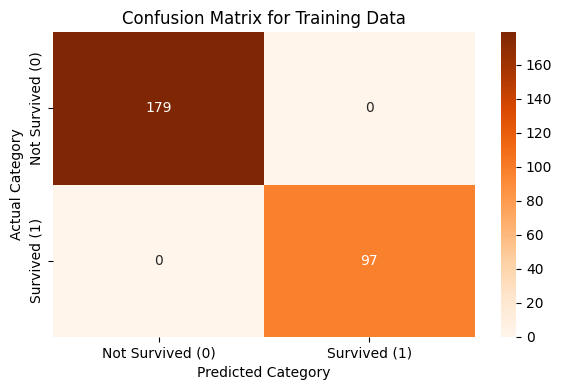

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
#  Make predictions on the training set
y_train_pred = model.predict(X_train)

#  Calculate confusion matrix for training data
conf_matrix_train = confusion_matrix(y_train, y_train_pred)

# Plot the confusion matrix
plt.figure(figsize=(6, 4))
sns.heatmap(conf_matrix_train, annot=True, fmt='d', cmap='Oranges',
            xticklabels=['Not Survived (0)', 'Survived (1)'],
            yticklabels=['Not Survived (0)', 'Survived (1)'])

plt.title('Confusion Matrix for Training Data')
plt.ylabel('Actual Category')
plt.xlabel('Predicted Category')
plt.tight_layout()
plt.show()

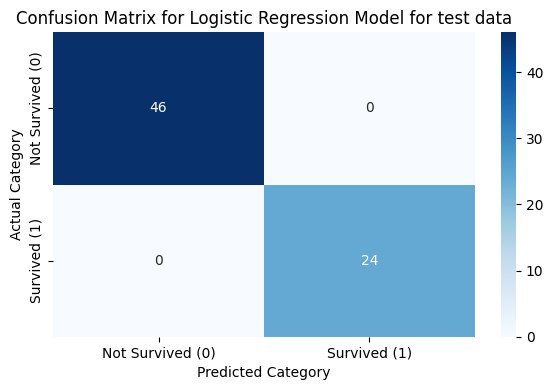

In [ ]:
# Create a labeled confusion matrix plot
plt.figure(figsize=(6, 4))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Not Survived (0)', 'Survived (1)'],
            yticklabels=['Not Survived (0)', 'Survived (1)'])

plt.title('Confusion Matrix for Logistic Regression Model for test data')
plt.ylabel('Actual Category')
plt.xlabel('Predicted Category')
plt.tight_layout()
plt.show()